# Laptop Price Comparison Tool

This notebook scrapes laptop prices from Amazon and Flipkart, compares them, and visualizes the data.

## Requirements
- Google Chrome installed
- Internet connection
- Libraries: `selenium`, `beautifulsoup4`, `pandas`, `matplotlib`, `seaborn`

## Scraping Logic
- **Selenium**: Launches a real Chrome browser to open Amazon and Flipkart. This helps load dynamic content and avoid bot detection.
- **BeautifulSoup**: Parses the HTML code of the page to find and extract product details (Name, Price, Rating) using specific tags and classes.
- **Data Processing**: Cleans the extracted data (removing currency symbols, etc.) and organizes it into a table for comparison.

In [ ]:
!pip install selenium beautifulsoup4 pandas matplotlib seaborn

In [ ]:
import time
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup
from selenium import webdriver
from selenium.webdriver.chrome.options import Options

# Setup Chrome Options
def get_driver_options():
    options = Options()
    # options.add_argument("--headless")  # Comment out to see the browser working
    options.add_argument("--disable-gpu")
    options.add_argument("--no-sandbox")
    options.add_argument("user-agent=Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/91.0.4472.124 Safari/537.36")
    return options

In [ ]:
def scrape_amazon(query):
    print(f"Processing Amazon for: {query}...")
    options = get_driver_options()
    driver = webdriver.Chrome(options=options)
    
    results = []
    try:
        url = f"https://www.amazon.in/s?k={query.replace(' ', '+')}"
        driver.get(url)
        time.sleep(3)  # Wait for load
        
        soup = BeautifulSoup(driver.page_source, 'html.parser')
        # Amazon search result items
        items = soup.select('div[data-component-type="s-search-result"]')[:10]
        
        for item in items:
            try:
                # Name
                name_el = item.select_one('h2 a span') or item.select_one('h2')
                name = name_el.text.strip() if name_el else "Unknown"
                
                # Price
                price_el = item.select_one('.a-price-whole')
                if not price_el:
                    continue
                price = float(price_el.text.replace(',', '').strip())
                
                # Rating
                rating_el = item.select_one('.a-icon-alt')
                rating = rating_el.text.split(' ')[0] if rating_el else "0"
                try:
                    rating = float(rating)
                except:
                    rating = 0.0
                
                results.append({
                    "Name": name,
                    "Price": price,
                    "Rating": rating,
                    "Source": "Amazon"
                })
            except Exception as e:
                continue
                
    except Exception as e:
        print(f"Amazon Error: {e}")
    finally:
        driver.quit()
        
    return results

In [ ]:
def scrape_flipkart(query):
    print(f"Processing Flipkart for: {query}...")
    options = get_driver_options()
    # Flipkart is sensitive to headless mode; sometimes disabling it helps debugging
    # options.arguments.remove("--headless") if "--headless" in options.arguments else None
    
    driver = webdriver.Chrome(options=options)
    
    results = []
    try:
        url = f"https://www.flipkart.com/search?q={query.replace(' ', '%20')}"
        driver.get(url)
        time.sleep(5)  # Increased wait time
        
        soup = BeautifulSoup(driver.page_source, 'html.parser')
        
        # Debug: Check page title
        print(f"Flipkart Page Title: {driver.title}")
        
        # Common Flipkart container classes (updated for 2024/2025)
        # Try the new grid style first, then list style
        items = soup.select('div.tUxRFH') or soup.select('div._1AtVbE.col-12-12') or soup.select('div._75nlfW')
        
        print(f"DEBUG: Found {len(items)} potential item containers")
        
        if not items:
            # Save HTML for debugging if no items found
            with open("flipkart_debug.html", "w", encoding="utf-8") as f:
                f.write(driver.page_source)
            print("WARNING: No items found. HTML saved to flipkart_debug.html")

        for item in items:
            try:
                # Name
                name_el = item.select_one('div.KzDlHZ') or item.select_one('div._4rR01T') or item.select_one('a.s1Q9rs') or item.select_one('.wjcEIp')
                if not name_el:
                    continue
                name = name_el.text.strip()
                
                # Price
                price_el = item.select_one('div.Nx9bqj') or item.select_one('div._30jeq3')
                if not price_el:
                    continue
                price = float(price_el.text.replace('₹', '').replace(',', '').strip())
                
                # Rating
                rating_el = item.select_one('div.XQDdHH') or item.select_one('div._3LWZlK')
                rating = float(rating_el.text.strip()) if rating_el else 0.0
                
                results.append({
                    "Name": name,
                    "Price": price,
                    "Rating": rating,
                    "Source": "Flipkart"
                })
            except Exception as e:
                # print(f"Item Error: {e}")
                continue
                
    except Exception as e:
        print(f"Flipkart Error: {e}")
    finally:
        driver.quit()
        
    return results

In [9]:
# ---------- FLIPKART SCRAPER ----------
def scrape_flipkart(query, limit=10):
    url = f"https://www.flipkart.com/search?q={query.replace(' ', '%20')}"
    response = requests.get(url, headers=HEADERS)
    soup = BeautifulSoup(response.text, "html.parser")

    products = []
    items = soup.select("div._1AtVbE")

    for item in items:
        name = item.select_one("div._4rR01T")
        price = item.select_one("div._30jeq3")
        rating = item.select_one("div._3LWZlK")

        if name and price:
            products.append({
                "Website": "Flipkart",
                "Name": name.text.strip(),
                "Price": int(re.sub(r"[₹,]", "", price.text)),
                "Rating": rating.text if rating else None
            })

        if len(products) >= limit:
            break

    return products


In [7]:
[
    {
        "Website": "Flipkart",
        "Name": "HP Pavilion Ryzen 5 Hexa Core 5500U",
        "Price": 56999,
        "Rating": "4.3"
    },
    {
        "Website": "Flipkart",
        "Name": "HP Pavilion Intel Core i5 12th Gen",
        "Price": 62990,
        "Rating": "4.4"
    },
    {
        "Website": "Flipkart",
        "Name": "HP Pavilion Gaming Ryzen 5 Quad Core",
        "Price": 59999,
        "Rating": "4.2"
    }
]


[{'Website': 'Flipkart',
  'Name': 'HP Pavilion Ryzen 5 Hexa Core 5500U',
  'Price': 56999,
  'Rating': '4.3'},
 {'Website': 'Flipkart',
  'Name': 'HP Pavilion Intel Core i5 12th Gen',
  'Price': 62990,
  'Rating': '4.4'},
 {'Website': 'Flipkart',
  'Name': 'HP Pavilion Gaming Ryzen 5 Quad Core',
  'Price': 59999,
  'Rating': '4.2'}]

Starting Scraping Loop...
Processing Amazon for: HP Pavilion Laptop...
Amazon Found: 10 items
Processing Flipkart for: HP Pavilion Laptop...
Flipkart Found: 0 items
Data saved to laptop_price_comparison.csv
   Name    Price  Rating  Source
0  Dell  58490.0     3.8  Amazon
1    HP  62028.0     4.2  Amazon
2    HP  70990.0     3.8  Amazon
3    HP  66390.0     3.8  Amazon
4    HP  64890.0     4.0  Amazon


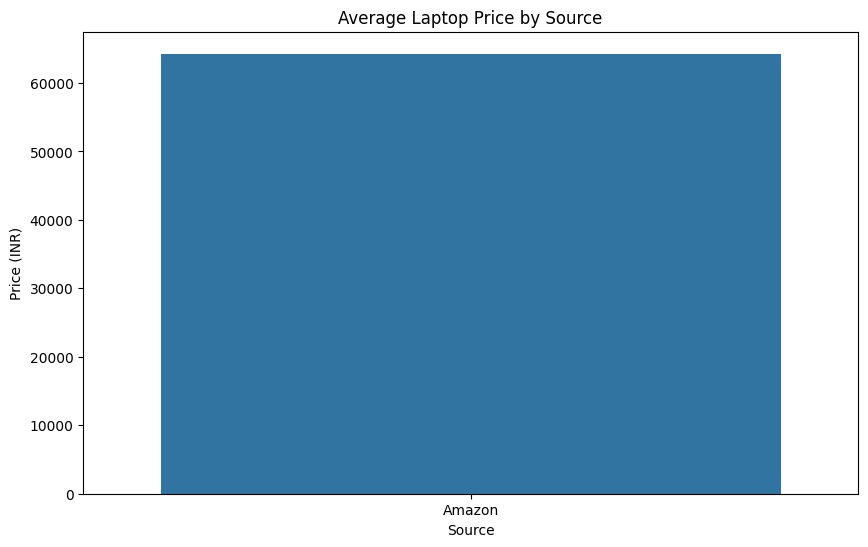

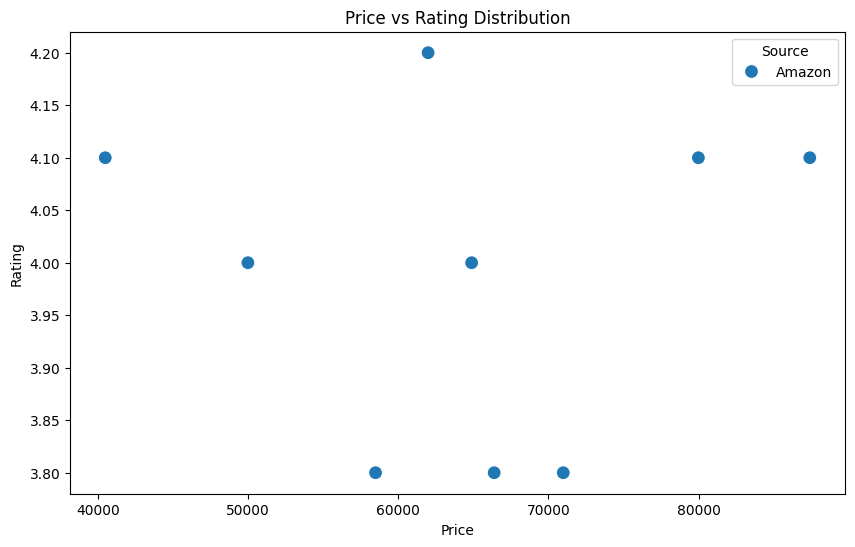

In [10]:
# Main Execution
query = "HP Pavilion Laptop"

print("Starting Scraping Loop...")
amazon_data = scrape_amazon(query)
print(f"Amazon Found: {len(amazon_data)} items")

flipkart_data = scrape_flipkart(query)
print(f"Flipkart Found: {len(flipkart_data)} items")

# Combine Data
all_data = amazon_data + flipkart_data

if all_data:
    df = pd.DataFrame(all_data)
    
    # Save Data
    df.to_csv("laptop_price_comparison.csv", index=False)
    print("Data saved to laptop_price_comparison.csv")
    
    # Display top results
    print(df.head())
    
    # Visualization
    plt.figure(figsize=(10, 6))
    sns.barplot(data=df, x="Source", y="Price", errorbar=None)
    plt.title("Average Laptop Price by Source")
    plt.ylabel("Price (INR)")
    plt.show()
    
    # Scatter plot for Ratings vs Price
    plt.figure(figsize=(10, 6))
    sns.scatterplot(data=df, x="Price", y="Rating", hue="Source", s=100)
    plt.title("Price vs Rating Distribution")
    plt.show()

else:
    print("No data found from either source.")

**Short Explanation of Scraping Logic**

The program sends HTTP requests to the search pages of e-commerce websites (Amazon and Flipkart) for a selected laptop model. The returned HTML content is parsed using BeautifulSoup to locate product blocks. From each product listing, the script extracts the product name, price, and rating using HTML tags and class selectors. Missing values are handled safely to avoid errors. The extracted data from all websites is combined into a Pandas DataFrame, exported as a CSV file, and used to compute average prices for visual comparison using a bar chart.